# Experiment Type Recovery Analysis

This notebook recomputes degradation and recovery metrics directly from the raw `baseline → chaos → recovery` measurements recorded in each experiment log. It then aggregates the results per experiment type, contrasts them with the success flags stored in the logs, and visualises overall recovery effectiveness alongside agent effort.

In [7]:
import json
from pathlib import Path
from typing import Dict, Any, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'axes.titlesize': 16,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

## 1. Select and Load Experiment Logs

Update `DATA_DIRECTORIES` to point to the batches you want to analyse. All JSON experiment logs inside the listed directories will be processed.

In [8]:
DATA_DIRECTORIES = [
    Path('DATASET_LOGS/gpt-5/batch_20251112_104955_app-smart-city'),
    Path('DATASET_LOGS/gpt-5/batch_20251113_090217_app-smart-manufacturing'),
]

available_files = []
for directory in DATA_DIRECTORIES:
    if not directory.exists():
        print(f'⚠️ Skipping missing directory: {directory}')
        continue
    matched = sorted(directory.glob('*.json'))
    available_files.extend(matched)
    print(f'✓ {directory} → {len(matched)} files')

if not available_files:
    raise RuntimeError('No JSON log files found. Update DATA_DIRECTORIES to valid batches.')

print(f"\nTotal: {len(available_files)} experiment logs across {len({fp.parent for fp in available_files})} directory(ies).")

✓ DATASET_LOGS/gpt-5/batch_20251112_104955_app-smart-city → 21 files
✓ DATASET_LOGS/gpt-5/batch_20251113_090217_app-smart-manufacturing → 14 files

Total: 35 experiment logs across 2 directory(ies).


## 2. Metric Extraction Helpers

The helper functions below classify experiments and derive degradation and recovery metrics from the baseline, chaos, and recovery phases.

In [9]:
def classify_experiment(fault_type: Optional[str], target_mode: Optional[str]) -> str:
    '''Map raw fault type and target mode to high-level experiment categories.'''
    fault_type = (fault_type or 'unknown').lower()
    target_mode = (target_mode or '').lower()

    if fault_type == 'baseline':
        return 'Baseline'
    if fault_type == 'pod_failure':
        return 'Pod Failure (All Pods)' if target_mode == 'all_pods_app' else 'Pod Failure (One Pod)'
    if fault_type == 'cpu_stress':
        return 'Pod CPU Stress (All Pods)' if target_mode == 'all_pods_app' else 'Pod CPU Stress (One Pod)'
    if fault_type == 'memory_stress':
        return 'Pod Memory Stress (All Pods)' if target_mode == 'all_pods_app' else 'Pod Memory Stress (One Pod)'
    if fault_type == 'node_cpu_stress':
        return 'Node CPU Stress'
    if fault_type == 'node_mem_stress':
        return 'Node Memory Stress'
    return f'Other: {fault_type}'.title()


def compute_recovery_index(baseline: float, chaos: float, recovery: float, *, higher_is_better: bool) -> float:
    '''Return the recovery index (percentage of degradation regained).'''
    eps = 1e-9

    if higher_is_better:
        delta = baseline - chaos
        if abs(delta) < eps:
            return 100.0 if recovery >= baseline else 0.0
        progress = recovery - chaos
    else:
        delta = chaos - baseline
        if abs(delta) < eps:
            return 100.0 if recovery <= baseline else 0.0
        progress = chaos - recovery

    index = (progress / delta) * 100
    return float(np.clip(index, 0.0, 120.0))


def process_log(filepath: Path) -> Dict[str, Any]:
    with filepath.open() as f:
        data = json.load(f)

    baseline = data.get('baseline_metrics', {}) or {}
    chaos = data.get('chaos_metrics', {}) or {}
    recovery = data.get('recovery_metrics', {}) or {}
    recovery_eval = data.get('recovery_evaluation', {}) or {}
    location_eval = data.get('location_evaluation', {}) or {}

    baseline_lat = baseline.get('p95_latency_seconds') or 0.0
    baseline_sr = baseline.get('success_rate_percent') or 0.0
    chaos_lat = chaos.get('p95_latency_seconds', baseline_lat)
    chaos_sr = chaos.get('success_rate_percent', baseline_sr)
    recovery_lat = recovery.get('p95_latency_seconds', chaos_lat)
    recovery_sr = recovery.get('success_rate_percent', chaos_sr)

    latency_deg_pct = ((chaos_lat - baseline_lat) / baseline_lat * 100) if baseline_lat > 0 else 0.0
    success_deg_pct = ((baseline_sr - chaos_sr) / baseline_sr * 100) if baseline_sr > 0 else 0.0

    latency_recovery_pct = compute_recovery_index(baseline_lat, chaos_lat, recovery_lat, higher_is_better=False)
    success_recovery_pct = compute_recovery_index(baseline_sr, chaos_sr, recovery_sr, higher_is_better=True)

    latency_within_20 = recovery_lat <= baseline_lat * 1.20 if baseline_lat > 0 else True
    success_within_1 = abs(recovery_sr - baseline_sr) <= 1.0
    recovery_success = bool(latency_within_20 and success_within_1)

    chaos_config = data.get('chaos_config', {}) or {}
    target_cfg = chaos_config.get('target') or {}

    return {
        'file': filepath.name,
        'experiment_id': data.get('experiment_id'),
        'category': classify_experiment(
            chaos_config.get('fault_type', chaos_config.get('type')),
            target_cfg.get('mode')
        ),
        'baseline_latency': baseline_lat,
        'chaos_latency': chaos_lat,
        'recovery_latency': recovery_lat,
        'baseline_success_rate': baseline_sr,
        'chaos_success_rate': chaos_sr,
        'recovery_success_rate': recovery_sr,
        'latency_degradation_pct': latency_deg_pct,
        'success_degradation_pct': success_deg_pct,
        'latency_recovery_pct': latency_recovery_pct,
        'success_recovery_pct': success_recovery_pct,
        'within20_logged': bool(recovery_eval.get('within_20pct_baseline', False)),
        'within20_recalc': recovery_success,
        'latency_within_20pct': latency_within_20,
        'success_within_1pct': success_within_1,
        'recovery_success': recovery_success,
        'recovery_index_latency': latency_recovery_pct,
        'recovery_index_success': success_recovery_pct,
        'recovery_index_composite': (latency_recovery_pct + success_recovery_pct) / 2,
        'location_identified': bool(location_eval.get('location_identified', False)),
        'agent_duration_seconds': data.get('agent_duration_seconds', 0.0),
        'agent_steps': len(data.get('agent_trace', [])),
    }

In [18]:
records = [process_log(fp) for fp in available_files]
df = pd.DataFrame(records)
df.sort_values('category', inplace=True)

print(f"Processed {len(df)} experiments across {df['category'].nunique()} experiment types.")
df.head()

Processed 35 experiments across 9 experiment types.


,file,experiment_id,category,baseline_latency,chaos_latency,recovery_latency,baseline_success_rate,chaos_success_rate,recovery_success_rate,latency_degradation_pct,...,within20_recalc,latency_within_20pct,success_within_1pct,recovery_success,recovery_index_latency,recovery_index_success,recovery_index_composite,location_identified,agent_duration_seconds,agent_steps
21,exp_001-no-failure-baseline.json,exp_001-no-failure-baseline,Baseline,0.218,0.203,0.194,100.0,100.0,100.0,-6.880734,...,True,True,True,True,0.000000,100.0,50.000000,True,86.315222,7
3,exp_001-no-failure-baseline.json,exp_001-no-failure-baseline,Baseline,0.425,0.445,0.439,100.0,100.0,100.0,4.705882,...,True,True,True,True,30.000000,100.0,65.000000,True,255.950596,11
7,exp_002-no-failure-baseline.json,exp_002-no-failure-baseline,Baseline,0.449,0.397,0.402,100.0,100.0,100.0,-11.581292,...,True,True,True,True,9.615385,100.0,54.807692,True,124.273516,7
11,exp_003-no-failure-baseline.json,exp_003-no-failure-baseline,Baseline,0.417,0.453,0.431,100.0,100.0,100.0,8.633094,...,True,True,True,True,61.111111,100.0,80.555556,True,361.926017,14
34,exp_014-chaos-node-cpu-stress-edge-site-2-work...,exp_014-chaos-node-cpu-stress-edge-site-2-work...,Node CPU Stress,0.216,0.738,0.193,100.0,100.0,100.0,241.666667,...,True,True,True,True,104.406130,100.0,102.203065,True,273.947507,11


## 3. Degradation and Recovery Overview

Average chaos degradation relative to baseline (positive ⇒ worse) and the percentage of that degradation that the system recovered.

In [25]:
degradation_summary = (
    df.groupby('category')[
        ['latency_degradation_pct', 'success_degradation_pct', 'latency_recovery_pct', 'success_recovery_pct']
    ]
    .mean()
    .rename(columns={
        'latency_degradation_pct': 'Latency Δ during chaos (%)',
        'success_degradation_pct': 'Success-rate Δ during chaos (%)',
        'latency_recovery_pct': 'Latency recovery (%)',
        'success_recovery_pct': 'Success-rate recovery (%)',
    })
    .round(2)
)

degradation_summary

,Latency Δ during chaos (%),Success-rate Δ during chaos (%),Latency recovery (%),Success-rate recovery (%)
category,,,,
Baseline,-1.28,0.00,25.18,100.00
Node CPU Stress,105.70,0.00,89.95,100.00
Node Memory Stress,95.06,1.07,67.31,100.00
Pod CPU Stress (All Pods),121.57,0.77,106.79,66.67
Pod CPU Stress (One Pod),-3.41,0.25,40.00,100.00
Pod Failure (All Pods),-17.34,48.19,71.70,101.38
Pod Failure (One Pod),1.10,0.18,85.00,100.00
Pod Memory Stress (All Pods),134.69,1.68,37.10,100.00
Pod Memory Stress (One Pod),3.84,0.00,22.45,75.00


## 4. Baseline → Chaos → Recovery Levels

Average p95 latency (left) and success rate (right) across experiment types.

/tmp/ipykernel_1396000/19904626.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_1396000/19904626.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


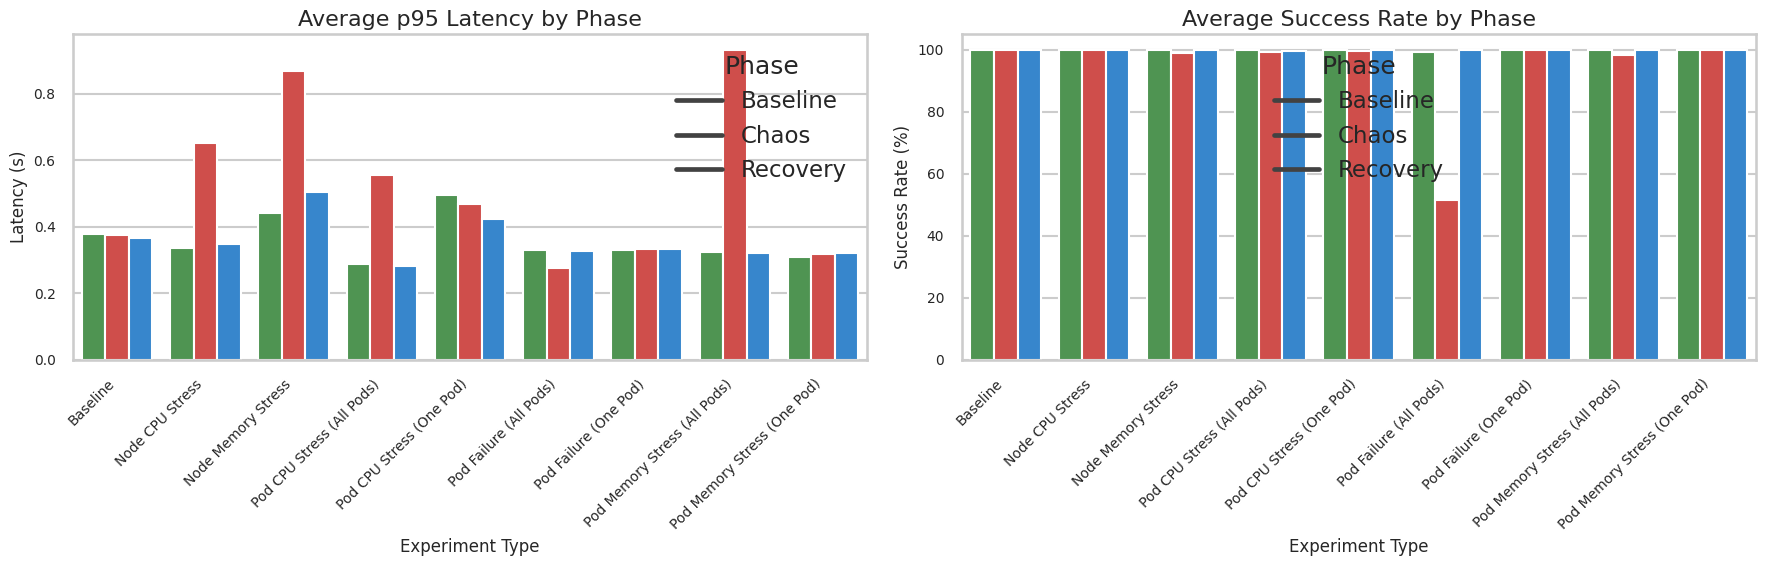

In [20]:
latency_levels = (
    df.groupby('category')[['baseline_latency', 'chaos_latency', 'recovery_latency']]
      .mean()
      .reset_index()
      .melt(id_vars='category', var_name='phase', value_name='latency_seconds')
)

success_levels = (
    df.groupby('category')[['baseline_success_rate', 'chaos_success_rate', 'recovery_success_rate']]
      .mean()
      .reset_index()
      .melt(id_vars='category', var_name='phase', value_name='success_rate')
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=latency_levels,
    x='category', y='latency_seconds', hue='phase',
    hue_order=['baseline_latency', 'chaos_latency', 'recovery_latency'],
    palette=['#43a047', '#e53935', '#1e88e5'],
    ax=axes[0]
)
axes[0].set_title('Average p95 Latency by Phase')
axes[0].set_xlabel('Experiment Type')
axes[0].set_ylabel('Latency (s)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend(title='Phase', labels=['Baseline', 'Chaos', 'Recovery'])

sns.barplot(
    data=success_levels,
    x='category', y='success_rate', hue='phase',
    hue_order=['baseline_success_rate', 'chaos_success_rate', 'recovery_success_rate'],
    palette=['#43a047', '#e53935', '#1e88e5'],
    ax=axes[1]
)
axes[1].set_title('Average Success Rate by Phase')
axes[1].set_xlabel('Experiment Type')
axes[1].set_ylabel('Success Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend(title='Phase', labels=['Baseline', 'Chaos', 'Recovery'])

plt.tight_layout()
plt.show()

## 5. Recovery vs. Location Identification

Compare how often the system recovered (latency ≤ 20% & success rate ≤ 1%) with how often the agent identified the correct problem location.

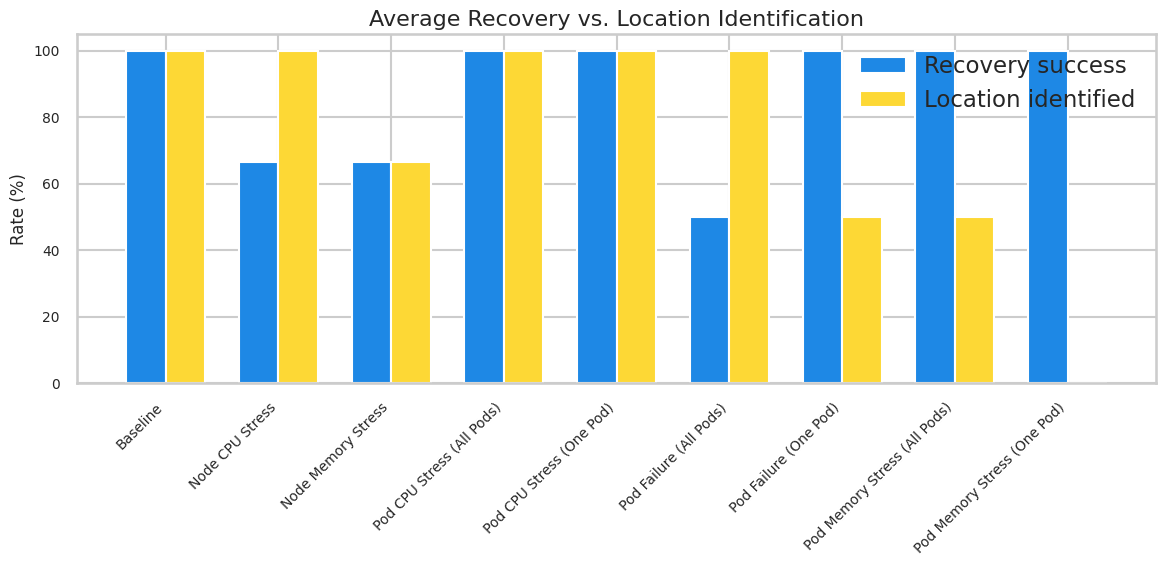

In [12]:
recovery_vs_location = (
    df.groupby('category')[['recovery_success', 'location_identified']]
      .mean()
      .rename(columns={'recovery_success': 'Recovery success', 'location_identified': 'Location identified'})
      .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.35
positions = np.arange(len(recovery_vs_location))

ax.bar(positions - width/2, recovery_vs_location['Recovery success'] * 100, width, label='Recovery success', color='#1e88e5')
ax.bar(positions + width/2, recovery_vs_location['Location identified'] * 100, width, label='Location identified', color='#fdd835')

ax.set_xticks(positions)
ax.set_xticklabels(recovery_vs_location['category'], rotation=45, ha='right')
ax.set_ylabel('Rate (%)')
ax.set_title('Average Recovery vs. Location Identification')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Within-20%-of-Baseline Agreement

Contrast the `within_20pct_baseline` flag stored in the logs with the value rederived from the baseline/chaos/recovery metrics.

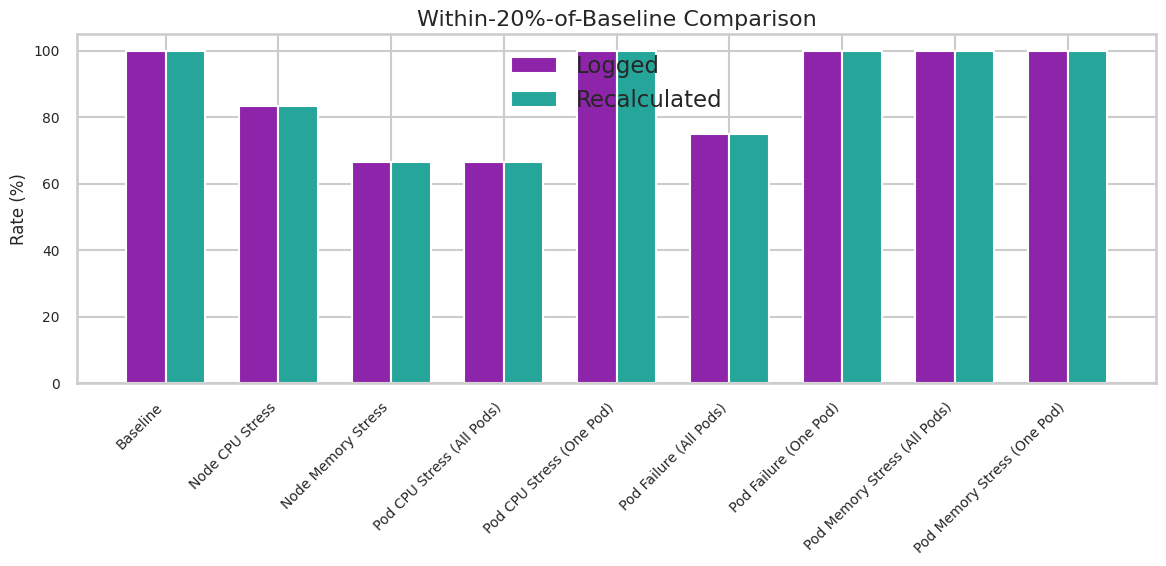

Experiments where logged and recalculated values differ: 0


In [21]:
within20_summary = (
    df.groupby('category')[['within20_logged', 'within20_recalc']]
      .mean()
      .rename(columns={'within20_logged': 'Logged within 20%', 'within20_recalc': 'Recalculated within 20%'})
      .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.35
positions = np.arange(len(within20_summary))

ax.bar(positions - width/2, within20_summary['Logged within 20%'] * 100, width, label='Logged', color='#8e24aa')
ax.bar(positions + width/2, within20_summary['Recalculated within 20%'] * 100, width, label='Recalculated', color='#26a69a')

ax.set_xticks(positions)
ax.set_xticklabels(within20_summary['category'], rotation=45, ha='right')
ax.set_ylabel('Rate (%)')
ax.set_title('Within-20%-of-Baseline Comparison')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Experiments where logged and recalculated values differ: {(df['within20_logged'] != df['within20_recalc']).sum()}")

## 7. Agent Effort: Execution Time and Rounds

Average agent runtime and number of steps per experiment type.

/tmp/ipykernel_1396000/2669893608.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_1396000/2669893608.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


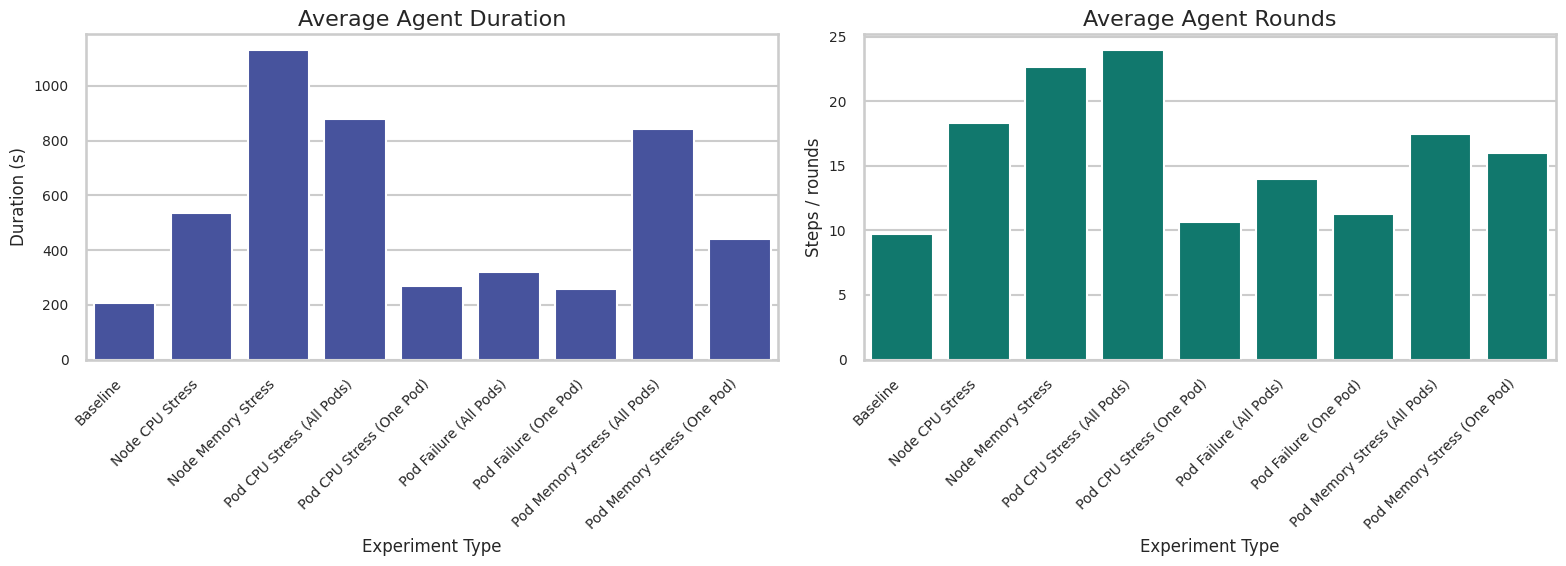

In [22]:
agent_stats = df.groupby('category')[['agent_duration_seconds', 'agent_steps']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=agent_stats, x='category', y='agent_duration_seconds', color='#3949ab', ax=axes[0])
axes[0].set_title('Average Agent Duration')
axes[0].set_xlabel('Experiment Type')
axes[0].set_ylabel('Duration (s)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

sns.barplot(data=agent_stats, x='category', y='agent_steps', color='#00897b', ax=axes[1])
axes[1].set_title('Average Agent Rounds')
axes[1].set_xlabel('Experiment Type')
axes[1].set_ylabel('Steps / rounds')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 8. Threshold Compliance per Experiment

Each point shows whether an experiment satisfied the latency ≤ 20% and success rate ≤ 1% thresholds.

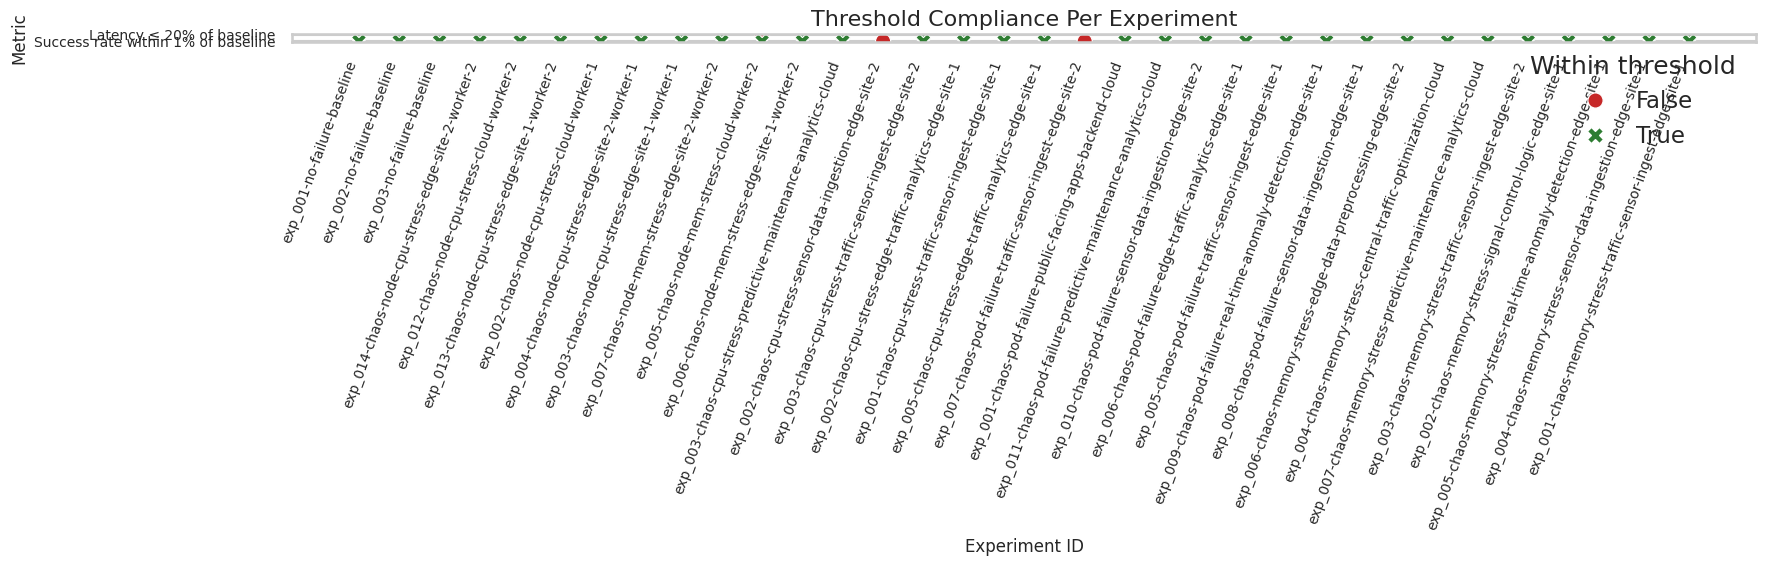

In [23]:
compliance_long = (
    df[['experiment_id', 'category', 'latency_within_20pct', 'success_within_1pct']]
      .melt(id_vars=['experiment_id', 'category'], var_name='metric', value_name='within_threshold')
)
label_map = {
    'latency_within_20pct': 'Latency ≤ 20% of baseline',
    'success_within_1pct': 'Success rate within 1% of baseline'
}
compliance_long['metric'] = compliance_long['metric'].map(label_map)

plt.figure(figsize=(18, 6))
sns.scatterplot(
    data=compliance_long,
    x='experiment_id', y='metric', hue='within_threshold', style='within_threshold',
    palette={True: '#2e7d32', False: '#c62828'}, s=120
)
plt.xticks(rotation=70, ha='right')
plt.xlabel('Experiment ID')
plt.ylabel('Metric')
plt.title('Threshold Compliance Per Experiment')
plt.legend(title='Within threshold')
plt.tight_layout()
plt.show()

## 9. Aggregate Metrics Across All Experiments

Overall averages for degradation, recovery, and success-related metrics across the entire dataset.

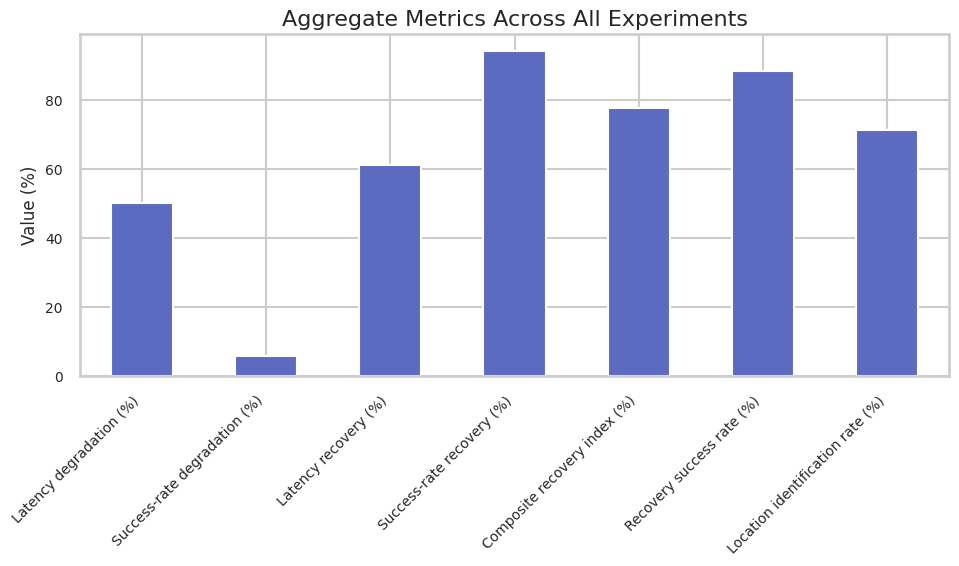

,Value
Latency degradation (%),50.23
Success-rate degradation (%),5.90
Latency recovery (%),61.36
Success-rate recovery (%),94.44
Composite recovery index (%),77.90
Recovery success rate (%),88.57
Location identification rate (%),71.43


In [24]:
overall_metrics = {
    'Latency degradation (%)': df['latency_degradation_pct'].mean(),
    'Success-rate degradation (%)': df['success_degradation_pct'].mean(),
    'Latency recovery (%)': df['latency_recovery_pct'].mean(),
    'Success-rate recovery (%)': df['success_recovery_pct'].mean(),
    'Composite recovery index (%)': df['recovery_index_composite'].mean(),
    'Recovery success rate (%)': df['recovery_success'].mean() * 100,
    'Location identification rate (%)': df['location_identified'].mean() * 100,
}

overall_series = pd.Series(overall_metrics).round(2)

plt.figure(figsize=(10, 6))
overall_series.plot(kind='bar', color='#5c6bc0')
plt.title('Aggregate Metrics Across All Experiments')
plt.ylabel('Value (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

overall_series.to_frame('Value')

## 10. Export Processed Dataset

Save the processed per-experiment dataset for downstream analysis.

In [17]:
output_path = Path('processed_experiments.csv')
df.to_csv(output_path, index=False)
print(f'Saved processed dataset to {output_path.resolve()}')

Saved processed dataset to /home/avgerinos/projects/kub-mitigation-agent/processed_experiments.csv


### Key Takeaways

- **Degradation vs. recovery:** The summary table quantifies average chaos degradation relative to baseline and how much of that degradation the system regained.
- **Recovery vs. detection:** Comparing recovery success with location identification rates indicates whether the agent not only recovers the system but also diagnoses the fault.
- **Agent effort:** Runtime and step counts highlight which experiment types require the most effort from the agent.
- **Threshold compliance:** The scatter plot shows any experiments falling outside the latency or success-rate thresholds, while the within-20% comparison validates log integrity.
- **Global view:** The final bar chart aggregates the most important metrics across the entire dataset for a quick health check.